### **Overview**
This project addresses one of the most critical challenges in the banking and financial sector evaluating loan applications efficiently and accurately.

Traditional manual processes are slow, inconsistent, and prone to human bias.

### **Project Objective**
The goal is to train a binary classification model using features such as:

* Annual Income
* Credit Score
* Total Assets
* Loan Amount
* Employment Information  

The model supports faster, fairer, and data-driven lending decisions.

### **Business Impact**
* Identify low-risk applicants for approval
* Flag high-risk applicants
* Reduce manual review time
* Minimize human error
* Ensure consistent decision criteria

## Step 1 : Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"C:\Users\Kshitij\Downloads\loan_approval_dataset (1).csv",index_col=0)
df

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
loan_id,,,,,,,,,,,,
1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
2,-,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
4,3,Graduate,NaN,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...
4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected


In [3]:
df.describe(include="all")

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
count,4269,4269,4251,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03,4269
unique,7,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,4,Graduate,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Approved
freq,752,2144,2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2656
mean,NaN,NaN,NaN,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06,NaN
std,NaN,NaN,NaN,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06,NaN
min,NaN,NaN,NaN,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00,NaN
25%,NaN,NaN,NaN,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06,NaN
50%,NaN,NaN,NaN,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06,NaN
75%,NaN,NaN,NaN,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06,NaN


In [4]:
df.columns

Index([' no_of_dependents', ' education', ' self_employed', ' income_annum',
       ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

In [5]:
df.dtypes

no_of_dependents            object
education                   object
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                 object
dtype: object

## Step 2 : Data Cleaning & Preprocessing

In [6]:
# Feature Selection - Eliminating "education" based on domain knowledge
df.drop(" education",axis=1,inplace=True)

In [7]:
df.shape

(4269, 11)

In [8]:
# Converying datatype
df[' no_of_dependents'].unique()

array(['2', '-', '3', '5', '0', '4', '1'], dtype=object)

In [9]:
df[' no_of_dependents'].value_counts()

 no_of_dependents
4    752
3    727
2    708
0    708
1    697
5    673
-      4
Name: count, dtype: int64

In [10]:
df[' no_of_dependents'].replace("-",0,inplace=True)

In [11]:
df[' no_of_dependents'].unique()

array(['2', 0, '3', '5', '0', '4', '1'], dtype=object)

In [12]:
df[' no_of_dependents'] = df[' no_of_dependents'].astype("int")

In [13]:
df.dtypes

no_of_dependents             int64
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                 object
dtype: object

In [14]:
# Handling missing Values
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4269 entries, 1 to 4269
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0    no_of_dependents          4269 non-null   int64 
 1    self_employed             4251 non-null   object
 2    income_annum              4269 non-null   int64 
 3    loan_amount               4269 non-null   int64 
 4    loan_term                 4269 non-null   int64 
 5    cibil_score               4269 non-null   int64 
 6    residential_assets_value  4269 non-null   int64 
 7    commercial_assets_value   4269 non-null   int64 
 8    luxury_assets_value       4269 non-null   int64 
 9    bank_asset_value          4269 non-null   int64 
 10   loan_status               4269 non-null   object
dtypes: int64(9), object(2)
memory usage: 400.2+ KB


In [15]:
df.isnull().sum()

no_of_dependents             0
self_employed               18
income_annum                 0
loan_amount                  0
loan_term                    0
cibil_score                  0
residential_assets_value     0
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
loan_status                  0
dtype: int64

In [16]:
df[' self_employed'].unique()

array([' No', ' Yes', nan], dtype=object)

In [17]:
df[' self_employed'].value_counts()

 self_employed
Yes    2150
No     2101
Name: count, dtype: int64

In [18]:
df[' self_employed'].fillna(' No',inplace = True)

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
for i in df.columns:
    print(f"{i} : {df[i].unique()}")
    print("-------------------------------------------------------------")

 no_of_dependents : [2 0 3 5 4 1]
-------------------------------------------------------------
 self_employed : [' No' ' Yes']
-------------------------------------------------------------
 income_annum : [9600000 4100000 9100000 8200000 9800000 4800000 8700000 5700000  800000
 1100000 2900000 6700000 5000000 1900000 4700000  500000 2700000 6300000
 5800000 6500000 4900000 3100000 2400000 7000000 9000000 8400000 1700000
 1600000 8000000 3600000 1500000 7800000 1400000 4200000 5500000 9500000
 7300000 3800000 5100000 4300000 9300000 7400000 8500000 8800000 3300000
 3900000 8300000 5600000 5300000 2600000  700000 3500000 9900000 3000000
 6800000 2000000 1000000  300000 6600000 9400000 4400000  400000 6200000
 9700000 7100000  600000 7200000  900000  200000 1800000 4600000 2200000
 2500000 8600000 4000000 5200000 8900000 1300000 4500000 8100000 9200000
 2800000 7500000 6400000 6900000 7700000 3200000 7900000 5900000 3400000
 2100000 3700000 5400000 2300000 7600000 6000000 6100000 1200000

In [21]:
df.columns

Index([' no_of_dependents', ' self_employed', ' income_annum', ' loan_amount',
       ' loan_term', ' cibil_score', ' residential_assets_value',
       ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value',
       ' loan_status'],
      dtype='object')

In [22]:
df.loc[df[' residential_assets_value']<0,' residential_assets_value'] = 0

In [23]:
df[df[' residential_assets_value']<0]

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
loan_id,,,,,,,,,,,


In [24]:
df.dtypes

no_of_dependents             int64
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                 object
dtype: object

In [25]:
# Data Encoding
df[' self_employed'] = df[' self_employed'].map({' No':0,' Yes':1})

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4269 entries, 1 to 4269
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0    no_of_dependents          4269 non-null   int64 
 1    self_employed             4269 non-null   int64 
 2    income_annum              4269 non-null   int64 
 3    loan_amount               4269 non-null   int64 
 4    loan_term                 4269 non-null   int64 
 5    cibil_score               4269 non-null   int64 
 6    residential_assets_value  4269 non-null   int64 
 7    commercial_assets_value   4269 non-null   int64 
 8    luxury_assets_value       4269 non-null   int64 
 9    bank_asset_value          4269 non-null   int64 
 10   loan_status               4269 non-null   object
dtypes: int64(10), object(1)
memory usage: 400.2+ KB


In [27]:
df[' loan_status'] = df[' loan_status'].map({' Rejected':0,' Approved':1})
df

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
loan_id,,,,,,,,,,,
1,2,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
2,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
3,3,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
4,3,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
5,5,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0
...,...,...,...,...,...,...,...,...,...,...,...
4265,5,1,1000000,2300000,12,317,2800000,500000,3300000,800000,0
4266,0,1,3300000,11300000,20,559,4200000,2900000,11000000,1900000,1
4267,2,0,6500000,23900000,18,457,1200000,12400000,18100000,7300000,0


## Step 3 : EDA 

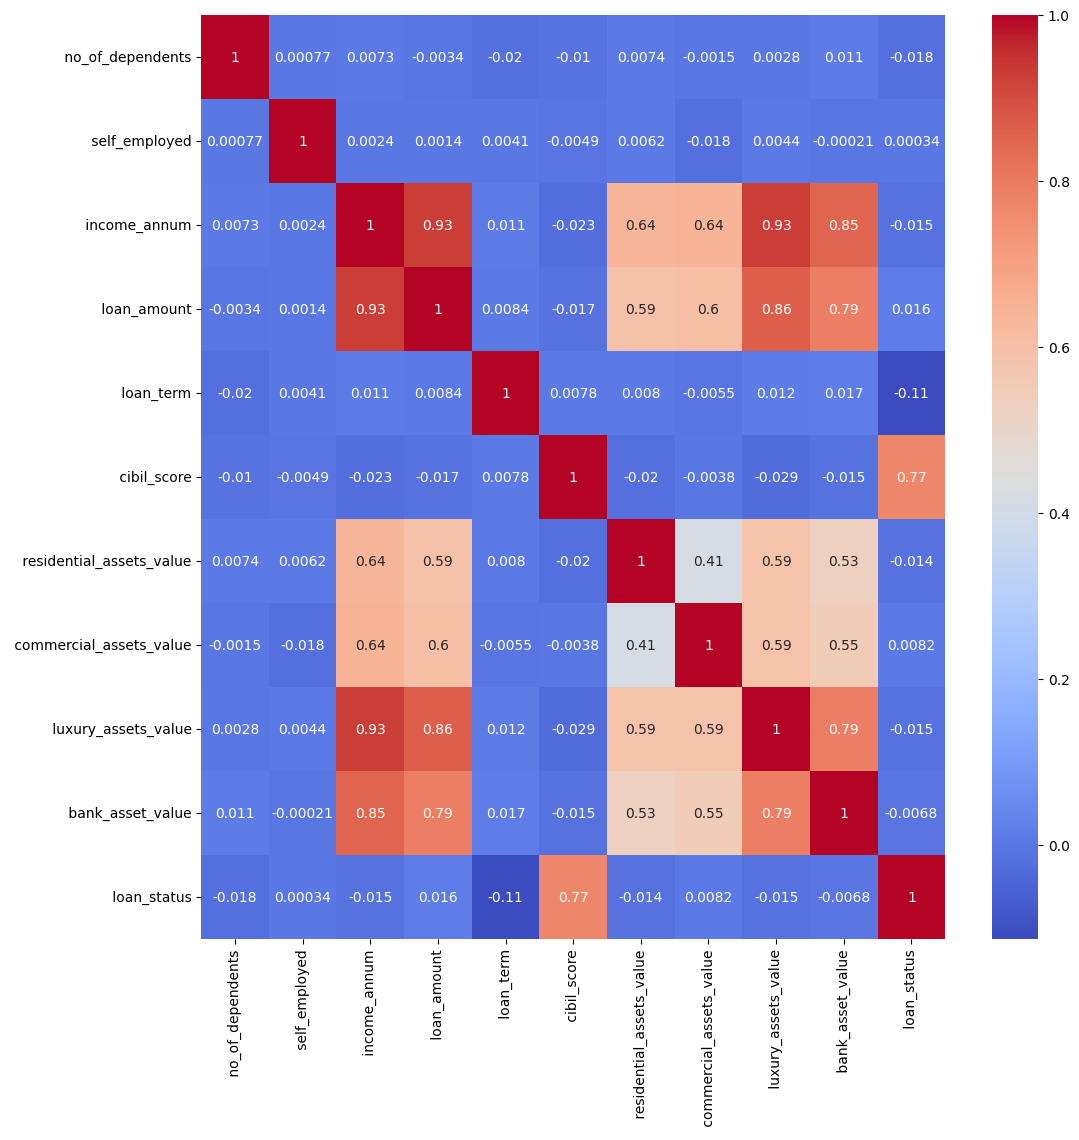

In [28]:
plt.figure(figsize=(12, 12))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

## Q1. How cibil score impacts loan status

In [29]:
def cibil(x):
    if x<=450:
        return "Low"
    elif x<=600:
        return "Medium"
    elif x<=750:
        return "High"
    elif x<=900 :
        return "Excellent"

In [30]:
df["cibil_grp"] = df[" cibil_score"].apply(cibil)

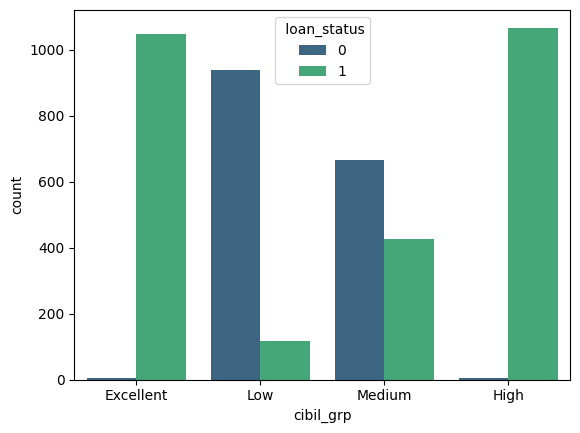

In [31]:
sns.countplot(data=df,x="cibil_grp",hue = " loan_status",palette="viridis");
plt.show()

## Insights : 
- High Cibil Score Has More Chances of getTing Loan Approved
- Low & Medium Score Has 

## How does loan amt & income relate with each other

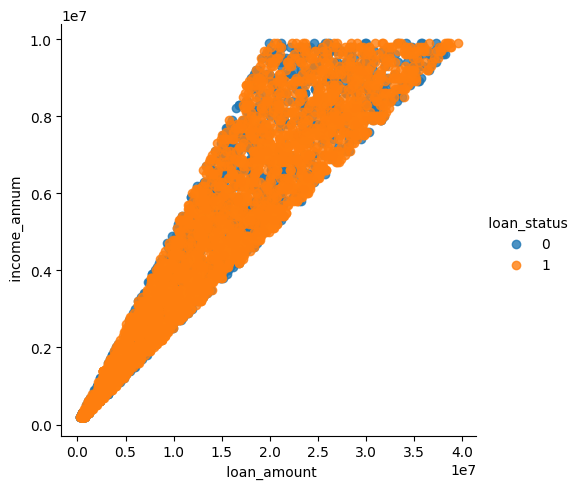

In [32]:
sns.lmplot(data=df, x =" loan_amount", y = " income_annum",hue = " loan_status",fit_reg=False);

## How the loan term plan helps to understand loan status of the individual

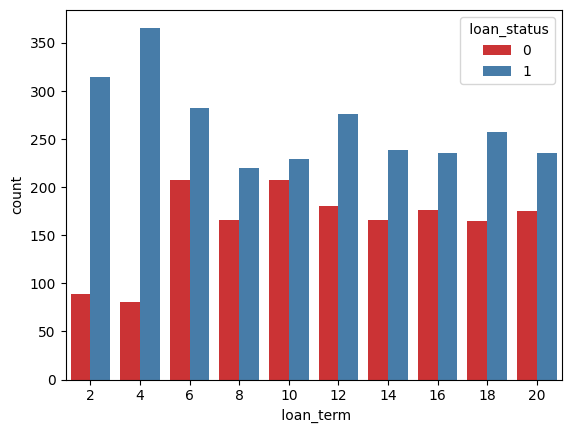

In [33]:
sns.countplot(data=df,x = " loan_term", hue = " loan_status",palette= "Set1");

## Insights : 
- If You are taking loan for short period of time than chances of loan getting approved is high

## Distribution of loan amount applications so far

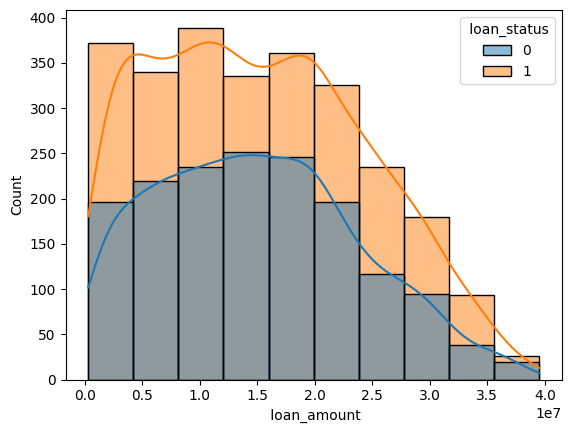

In [34]:
sns.histplot(data=df,x = " loan_amount", bins = 10, edgecolor = "black",hue=" loan_status",color="yellow",kde=True);

## Insights
- High Amount of loans has less chance of getting Approval

## Assets relation with loan status

In [35]:
df.columns

Index([' no_of_dependents', ' self_employed', ' income_annum', ' loan_amount',
       ' loan_term', ' cibil_score', ' residential_assets_value',
       ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value',
       ' loan_status', 'cibil_grp'],
      dtype='object')

In [36]:
col = [' residential_assets_value',
       ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value']

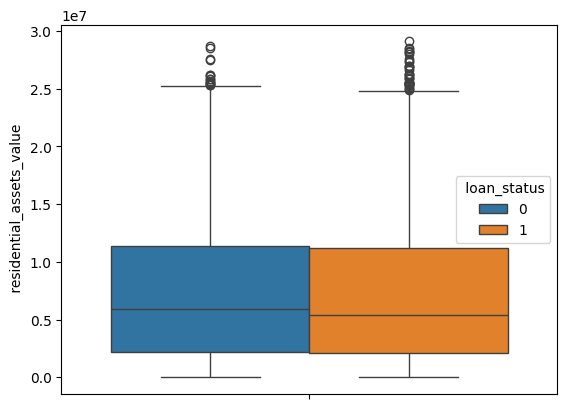

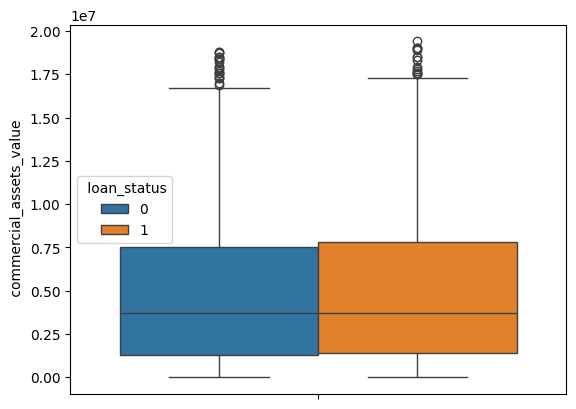

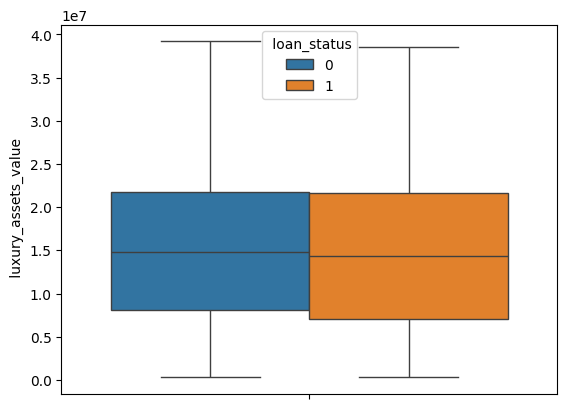

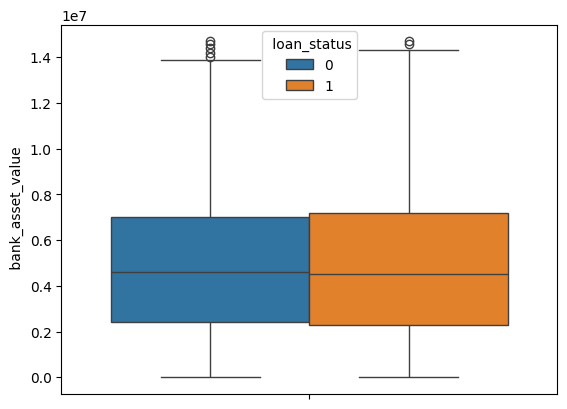

In [37]:
for i in df[col]:
    sns.boxplot(data=df, y=df[i],hue=df[" loan_status"])
    plt.show()

In [38]:
df

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,cibil_grp
loan_id,,,,,,,,,,,,
1,2,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1,Excellent
2,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0,Low
3,3,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0,Medium
4,3,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0,Medium
5,5,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0,Low
...,...,...,...,...,...,...,...,...,...,...,...,...
4265,5,1,1000000,2300000,12,317,2800000,500000,3300000,800000,0,Low
4266,0,1,3300000,11300000,20,559,4200000,2900000,11000000,1900000,1,Medium
4267,2,0,6500000,23900000,18,457,1200000,12400000,18100000,7300000,0,Medium


In [39]:
df.drop("cibil_grp",axis=1,inplace=True);

<Axes: xlabel=' loan_status', ylabel='count'>

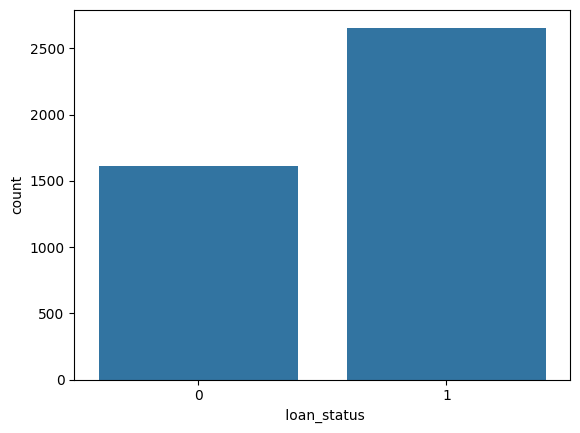

In [40]:
# How many Applicants we have for each loan status
sns.countplot(data=df, x = " loan_status")

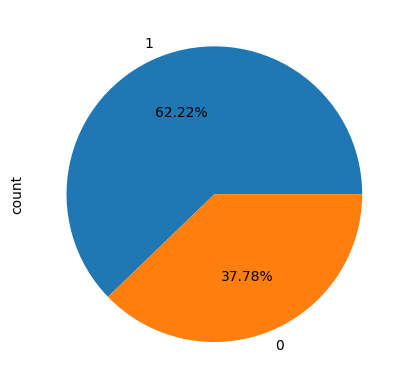

In [41]:
df[" loan_status"].value_counts().plot(kind='pie',autopct='%.2f%%');

In [42]:
df.columns

Index([' no_of_dependents', ' self_employed', ' income_annum', ' loan_amount',
       ' loan_term', ' cibil_score', ' residential_assets_value',
       ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value',
       ' loan_status'],
      dtype='object')

In [43]:
x=df.iloc[:,0:-1]
y=df.iloc[:,-1]
print(x.shape)
print(y.shape)

(4269, 10)
(4269,)


### Scaling

In [44]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
x = sc.fit_transform(x)

In [45]:
x

array([[-0.2941017 , -1.00728821,  1.61797904, ...,  2.877289  ,
         0.83202837,  0.93030441],
       [-1.4735476 ,  0.99276452, -0.34174956, ..., -0.63192107,
        -0.69499321, -0.51593638],
       [ 0.29562125, -1.00728821,  1.4398219 , ..., -0.10781827,
         1.99651964,  2.40731629],
       ...,
       [-0.2941017 , -1.00728821,  0.51340474, ...,  1.69236092,
         0.3266831 ,  0.71490685],
       [-0.88382465, -1.00728821, -0.34174956, ..., -0.97372725,
        -0.11274758,  0.25334064],
       [-0.88382465, -1.00728821,  1.47545332, ...,  1.55563845,
         2.26017804,  2.16114764]], shape=(4269, 10))

## Step 4 : Data Splitting

In [46]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)

In [47]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(2988, 10)
(1281, 10)
(2988,)
(1281,)


## Step 5 : Model Building

#### Training phase 
- i/p -> x,y
- o/p -> y
#### Testing phase( validation )
- i/p -> only x
- o/p -> y predicted on the basis of training eqn

In [48]:
from sklearn.linear_model import LogisticRegression 

classifier = LogisticRegression()

classifier.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [49]:
# Predictions
y_pred_prob = classifier.predict_proba(x_test)
y_pred_prob

array([[0.97155231, 0.02844769],
       [0.1586831 , 0.8413169 ],
       [0.97586291, 0.02413709],
       ...,
       [0.05529406, 0.94470594],
       [0.84676204, 0.15323796],
       [0.01465632, 0.98534368]], shape=(1281, 2))

In [50]:
y_pred = classifier.predict(x_test)
y_pred

array([0, 1, 0, ..., 1, 0, 1], shape=(1281,))

In [51]:
#list(zip(y_test,y_pred))

[(0, np.int64(0)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (0, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (0, np.int64(0)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(0)),
 (0, np.int64(0)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (0, np.int64(0)),
 (0, np.int64(0)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (0, np.int64(1)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (0, np.int64(0)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (0, np.int64(0)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(0)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (1, np.int64(1)),
 (0, np.int64(0)),
 (1, np.int64(1)),
 (1, np.int64(0)),
 (0, np.int6

## Step 6 : Data Evaluation

In [56]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
confusion_matrix(y_test,y_pred)
print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.87      0.87      0.87       471
           1       0.92      0.92      0.92       810

    accuracy                           0.90      1281
   macro avg       0.90      0.90      0.90      1281
weighted avg       0.90      0.90      0.90      1281



[[410  61]
 [ 63 747]]


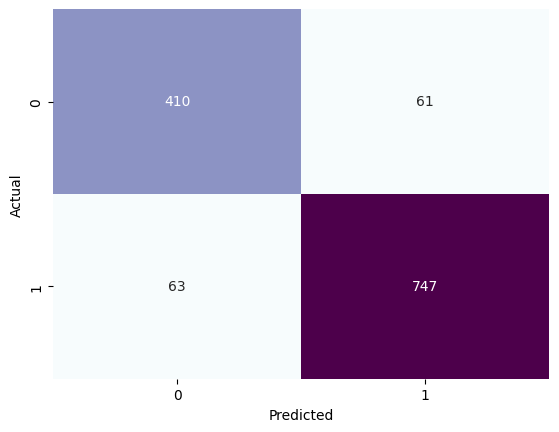

0.9032006245120999
              precision    recall  f1-score   support

           0       0.87      0.87      0.87       471
           1       0.92      0.92      0.92       810

    accuracy                           0.90      1281
   macro avg       0.90      0.90      0.90      1281
weighted avg       0.90      0.90      0.90      1281



In [57]:
cfm = confusion_matrix(y_test,y_pred)
print(cfm)

sns.heatmap(cfm, annot=True, fmt='g', cbar=False, cmap='BuPu')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))

## Step 7 : Model Tuning
#### Tuning is used to improve the performance of the model

In [58]:
# 1. Feature Selection

In [59]:
df.columns

Index([' no_of_dependents', ' self_employed', ' income_annum', ' loan_amount',
       ' loan_term', ' cibil_score', ' residential_assets_value',
       ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value',
       ' loan_status'],
      dtype='object')

In [62]:
x_new = df.loc[:,[' no_of_dependents', ' income_annum', ' loan_amount',
       ' loan_term', ' cibil_score', ' residential_assets_value',
       ' commercial_assets_value']]
print(x_new.shape)
y_new = df.loc[:," loan_status"]
print(y_new.shape)


(4269, 7)
(4269,)


In [63]:
scalar = StandardScaler()
x_new = scalar.fit_transform(x_new)

In [64]:
x_train_new,x_test_new,y_train_new,y_test_new = train_test_split(x_new,y_new,test_size=0.3,random_state=42)

In [65]:
log= LogisticRegression()

log.fit(x_train_new,y_train_new)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [66]:
y_pred_new = log.predict(x_test_new)

[[411  60]
 [ 62 748]]


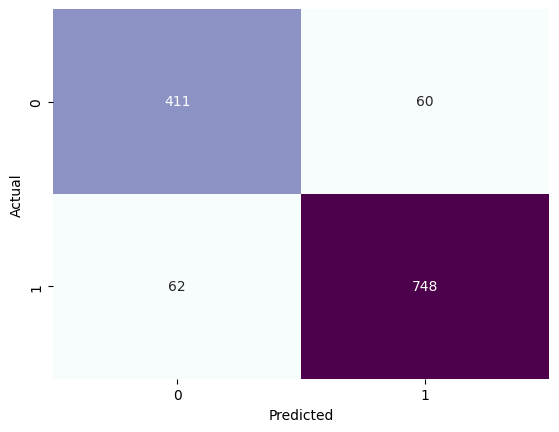

0.9047619047619048
              precision    recall  f1-score   support

           0       0.87      0.87      0.87       471
           1       0.93      0.92      0.92       810

    accuracy                           0.90      1281
   macro avg       0.90      0.90      0.90      1281
weighted avg       0.90      0.90      0.90      1281



In [68]:
cfm = confusion_matrix(y_test_new,y_pred_new)
print(cfm)

sns.heatmap(cfm, annot=True, fmt='g', cbar=False, cmap='BuPu')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
print(accuracy_score(y_test_new,y_pred_new))
print(classification_report(y_test_new,y_pred_new))

## Dedicated Approach - Adjustment of Threshold

In [70]:
# Store the predicted probabilities
y_pred_prob = classifier.predict_proba(x_test)
y_pred_prob[:,1]

array([0.02844769, 0.8413169 , 0.02413709, ..., 0.94470594, 0.15323796,
       0.98534368], shape=(1281,))

In [71]:
for a in np.arange(0.4,0.61,0.01):
    predict_mine = np.where(y_pred_prob[:,1] > a, 1, 0)
    cfm = confusion_matrix(y_test, predict_mine)
    total_err = cfm[0,1]+cfm[1,0]
    print("Errors at threshold ", a, ":",total_err, ", type 2 error :",cfm[1,0],", type 1 error:",cfm[0,1])

Errors at threshold  0.4 : 137 , type 2 error : 47 , type 1 error: 90
Errors at threshold  0.41000000000000003 : 138 , type 2 error : 50 , type 1 error: 88
Errors at threshold  0.42000000000000004 : 139 , type 2 error : 51 , type 1 error: 88
Errors at threshold  0.43000000000000005 : 139 , type 2 error : 52 , type 1 error: 87
Errors at threshold  0.44000000000000006 : 137 , type 2 error : 53 , type 1 error: 84
Errors at threshold  0.45000000000000007 : 135 , type 2 error : 54 , type 1 error: 81
Errors at threshold  0.4600000000000001 : 135 , type 2 error : 56 , type 1 error: 79
Errors at threshold  0.4700000000000001 : 132 , type 2 error : 58 , type 1 error: 74
Errors at threshold  0.4800000000000001 : 126 , type 2 error : 60 , type 1 error: 66
Errors at threshold  0.4900000000000001 : 127 , type 2 error : 62 , type 1 error: 65
Errors at threshold  0.5000000000000001 : 124 , type 2 error : 63 , type 1 error: 61
Errors at threshold  0.5100000000000001 : 123 , type 2 error : 65 , type 1 

## Test Data -> Unseen Data

In [89]:
newdf = pd.DataFrame(columns=df.columns[:-1])
print(newdf)
print(newdf.columns)

Empty DataFrame
Columns: [ no_of_dependents,  self_employed,  income_annum,  loan_amount,  loan_term,  cibil_score,  residential_assets_value,  commercial_assets_value,  luxury_assets_value,  bank_asset_value]
Index: []
Index([' no_of_dependents', ' self_employed', ' income_annum', ' loan_amount',
       ' loan_term', ' cibil_score', ' residential_assets_value',
       ' commercial_assets_value', ' luxury_assets_value',
       ' bank_asset_value'],
      dtype='object')


In [90]:
newdf[' no_of_dependents'] = [0,1,0,2,4]
newdf[' self_employed'] = [" Yes"," No",None," Yes"," Yes"]
newdf[' income_annum'] = [1000000,3500000,6000000,3800000,5600000]
newdf[' loan_amount'] = [3000000,5600000,15000000,9000000,19000000]
newdf[' loan_term'] = [2,8,10,12,20]
newdf[' cibil_score'] = [305,670,450,890,570]
newdf[' residential_assets_value'] = [3400000,0,4500000,5600000,0]
newdf[' commercial_assets_value'] = [890000,0,0,0,450000]
newdf[' luxury_assets_value'] = [89000,56000,4500000,0,0]
newdf[' bank_asset_value'] = [800000,780000,0,0,0]
newdf

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,0,Yes,1000000,3000000,2,305,3400000,890000,89000,800000
1,1,No,3500000,5600000,8,670,0,0,56000,780000
2,0,None,6000000,15000000,10,450,4500000,0,4500000,0
3,2,Yes,3800000,9000000,12,890,5600000,0,0,0
4,4,Yes,5600000,19000000,20,570,0,450000,0,0


In [91]:
test = newdf.copy()

## Handling Missing Values

In [92]:
newdf.isnull().sum()

no_of_dependents            0
self_employed               1
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
dtype: int64

In [93]:
newdf[" self_employed"].fillna(" No",inplace=True)

In [94]:
newdf.isnull().sum()

no_of_dependents            0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
dtype: int64

In [95]:
newdf[" self_employed"] = newdf[" self_employed"].map({" Yes":1, " No":0})

In [96]:
newdf

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,0,1,1000000,3000000,2,305,3400000,890000,89000,800000
1,1,0,3500000,5600000,8,670,0,0,56000,780000
2,0,0,6000000,15000000,10,450,4500000,0,4500000,0
3,2,1,3800000,9000000,12,890,5600000,0,0,0
4,4,1,5600000,19000000,20,570,0,450000,0,0


In [97]:
newdf = sc.transform(newdf)

In [98]:
np.set_printoptions(suppress = True)
classifier.predict_proba(newdf)

array([[0.9843685 , 0.0156315 ],
       [0.06475142, 0.93524858],
       [0.95533901, 0.04466099],
       [0.00037804, 0.99962196],
       [0.7169941 , 0.2830059 ]])

In [99]:
y_new = classifier.predict(newdf)
y_new

array([0, 1, 0, 1, 0])

In [101]:
test[" status_predicted"] = y_new
test

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,status_predicted
0,0,Yes,1000000,3000000,2,305,3400000,890000,89000,800000,0
1,1,No,3500000,5600000,8,670,0,0,56000,780000,1
2,0,None,6000000,15000000,10,450,4500000,0,4500000,0,0
3,2,Yes,3800000,9000000,12,890,5600000,0,0,0,1
4,4,Yes,5600000,19000000,20,570,0,450000,0,0,0


## Step 8 : Model Deployment

In [102]:
!pip install gradio

   ---------------------------------------- 0.0/31.0 MB ? eta -:--:--
   ------ --------------------------------- 4.7/31.0 MB 26.9 MB/s eta 0:00:01
   -------------- ------------------------- 11.3/31.0 MB 28.2 MB/s eta 0:00:01
   ------------------- -------------------- 15.5/31.0 MB 25.7 MB/s eta 0:00:01
   -------------------------- ------------- 20.2/31.0 MB 24.6 MB/s eta 0:00:01
   ---------------------------------- ----- 27.0/31.0 MB 26.2 MB/s eta 0:00:01
   ---------------------------------------  30.9/31.0 MB 26.9 MB/s eta 0:00:01
   ---------------------------------------- 31.0/31.0 MB 25.0 MB/s  0:00:01
   ---------------------------------------- 0.0/770.3 kB ? eta -:--:--
   ---------------------------------------- 770.3/770.3 kB 18.9 MB/s  0:00:00
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 4.0/4.0 MB 22.1 MB/s  0:00:00

   -- -------------------------------------  1/16 [semantic-version]
   ----- ----------

In [103]:
import joblib
joblib.dump(classifier, "Loan_model.pkl")

['Loan_model.pkl']

In [104]:
import gradio as gr
import joblib
 
# Load the trained model
model = joblib.load("loan_model.pkl")   
 
 
# Prediction Function
def predict_loan(
    no_of_dependents,
    self_employed,
    income_annum,
    loan_amount,
    loan_term,
    cibil_score,
    residential_assets_value,
    commercial_assets_value,
    luxury_assets_value,
    bank_asset_value,
):
 
    # Convert categorical input
    self_employed = 1 if self_employed == "Yes" else 0
 
    data = pd.DataFrame({
        "no_of_dependents":[no_of_dependents],
        "self_employed":[self_employed],
        "income_annum":[income_annum],
        "loan_amount":[loan_amount],
        "loan_term":[loan_term],
        "cibil_score":[cibil_score],
        "residential_assets_value":[residential_assets_value],
        "commercial_assets_value":[commercial_assets_value],
        "luxury_assets_value":[luxury_assets_value],
        "bank_asset_value":[bank_asset_value]
    })
 
    prediction = model.predict(data)[0]
 
    # If your model returns 0/1
    if prediction == 1:
        return "Loan Approved"
    else:
        return "Loan Rejected"
 
# Gradio UI
 
with gr.Blocks(theme=gr.themes.Soft()) as demo:
 
    gr.Markdown(
        """
        # 🏦 Loan Approval Prediction
 
        Enter the applicant details below to predict whether the loan is likely to be approved.
        """
    )
 
    with gr.Row():
 
        with gr.Column():
 
            no_of_dependents = gr.Slider(
                0,
                4,
                step=1,
                label="Number of Dependents"
            )
 
            self_employed = gr.Radio(
                ["Yes","No"],
                label="Self Employed"
            )
 
            income_annum = gr.Number(
                label="Annual Income (₹)"
            )
 
            loan_amount = gr.Number(
                label="Loan Amount (₹)"
            )
 
            loan_term = gr.Slider(
                1,
                20,
                step=1,
                label="Loan Term (Years)"
            )
 
        with gr.Column():
 
            cibil_score = gr.Slider(
                300,
                900,
                step=1,
                label="CIBIL Score"
            )
 
            residential_assets_value = gr.Number(
                label="Residential Assets Value (₹)"
            )
 
            commercial_assets_value = gr.Number(
                label="Commercial Assets Value (₹)"
            )
 
            luxury_assets_value = gr.Number(
                label="Luxury Assets Value (₹)"
            )
 
            bank_asset_value = gr.Number(
                label="Bank Asset Value (₹)"
            )
 
    predict_btn = gr.Button(
        "Predict Loan Status",
        variant="primary"
    )
 
    clear_btn = gr.ClearButton()
 
    output = gr.Textbox(
        label="Prediction",
        lines=2
    )
 
    predict_btn.click(
        fn=predict_loan,
        inputs=[
            no_of_dependents,
            self_employed,
            income_annum,
            loan_amount,
            loan_term,
            cibil_score,
            residential_assets_value,
            commercial_assets_value,
            luxury_assets_value,
            bank_asset_value
        ],
        outputs=output
    )
 
demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://4beca0ca9d7e7cdbf3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
